In [ ]:
!gdown --folder "https://drive.google.com/drive/folders/1zBgVbmyz3AyV-yH6GES4fs3WJSk0z0dA?usp=sharing"

Retrieving folder contents
Processing file 1b9n-VaRt1O4yCEtD_HbMyXxy-3UowutZ 300PLANETdataset
Processing file 15Bm-NBS6B6U0DKotHpcHUWvrv0qmm3XC part3-2.ipynb
Processing file 1LdBfrJemYxwdt8p_uVZ6oSOS2QLqKcMM planets_300.csv
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=1b9n-VaRt1O4yCEtD_HbMyXxy-3UowutZ
To: /content/PH1050-ENDSEM/300PLANETdataset
100% 3.03k/3.03k [00:00<00:00, 12.3MB/s]
Downloading...
From: https://drive.google.com/uc?id=15Bm-NBS6B6U0DKotHpcHUWvrv0qmm3XC
To: /content/PH1050-ENDSEM/part3-2.ipynb
100% 66.4k/66.4k [00:00<00:00, 64.5MB/s]
Downloading...
From: https://drive.google.com/uc?id=1LdBfrJemYxwdt8p_uVZ6oSOS2QLqKcMM
To: /content/PH1050-ENDSEM/planets_300.csv
100% 30.2k/30.2k [00:00<00:00, 67.3MB/s]
Download completed


In [ ]:

# 1. importing libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)


CSV_FILE = "/content/PH1050-ENDSEM/planets_300.csv"

A_COL = "a_AU"
M_COL = "M_star_solar"
T_COL = "T_years" #not T_true_years, this one has noise


In [ ]:
df = pd.read_csv(CSV_FILE) # creates datafrajne

# print("First five rows:")
#print(df.head())

#print("\nDataset information:")
#df.info()


DATA CLEANING

In [ ]:
# this keeps only the required columns, that are semi major axis, stellar mass and orbital period (with noise)
df = df[[A_COL, M_COL, T_COL]].copy()


# reemove rows with missing values
df = df.dropna()

# remove non-positive values
df = df[
    (df[A_COL] > 0) &
    (df[M_COL] > 0) &
    (df[T_COL] > 0)
].copy()

print("\nNumber of valid planets:", len(df))

# we did this cuz logarithms are only defined for positive numbers.

#We also remove missing values. Though not any in my dataset



Number of valid planets: 300


In [ ]:
#LOGARITHMIC TRANSFORMATION
df["log_a"] = np.log10(df["a_AU"])

df["log_M"] = np.log10(df["M_star_solar"])

df["log_T"] = np.log10(df["T_years"])

Training the linear regression modeL


In [ ]:
# 6. EXTRAPOLATION DATA SPLIT
# ============================================

# Training: planets with a < 1 AU
train_data = df[df[A_COL] < 1].copy()

# Testing: planets with a > 1 AU
test_data = df[df[A_COL] > 1].copy()

print("\nEXTRAPOLATION DATA SPLIT")

print("Training planets (a < 1 AU):",
      len(train_data))

print("Testing planets (a > 1 AU):",
      len(test_data))

#SO we are training on 9 planets and testing on 291



EXTRAPOLATION DATA SPLIT
Training planets (a < 1 AU): 9
Testing planets (a > 1 AU): 291


In [ ]:

# Independent variables
X_train = train_data[["log_a", "log_M"]]

X_test = test_data[["log_a", "log_M"]]

# Dependent variable
y_train = train_data["log_T"]

y_test = test_data["log_T"]



In [ ]:
# ============================================
#  TRAIN LINEAR REGRESSION MODEL
# ============================================

model = LinearRegression()

model.fit(X_train, y_train)

print("\nMODEL TRAINED SUCCESSFULLY")


MODEL TRAINED SUCCESSFULLY


In [ ]:
# ============================================
# PREDICT TEST DATA
# ============================================

y_pred = model.predict(X_test)

In [ ]:
# DISPLAY REGRESSION COEFFICIENTS
# ============================================

intercept = model.intercept_

beta_a, beta_M = model.coef_

print("\nREGRESSION COEFFICIENTS")

print("Intercept:", intercept)

print("Coefficient of log(a):", beta_a)

print("Coefficient of log(M):", beta_M)

print("\nRegression equation:")

print(
    f"log(T) = {intercept:.4f}"
    f" + ({beta_a:.4f}) log(a)"
    f" + ({beta_M:.4f}) log(M)"
)


REGRESSION COEFFICIENTS
Intercept: 0.007552896822527244
Coefficient of log(a): 1.5132906231185745
Coefficient of log(M): -0.44539589500389826

Regression equation:
log(T) = 0.0076 + (1.5133) log(a) + (-0.4454) log(M)


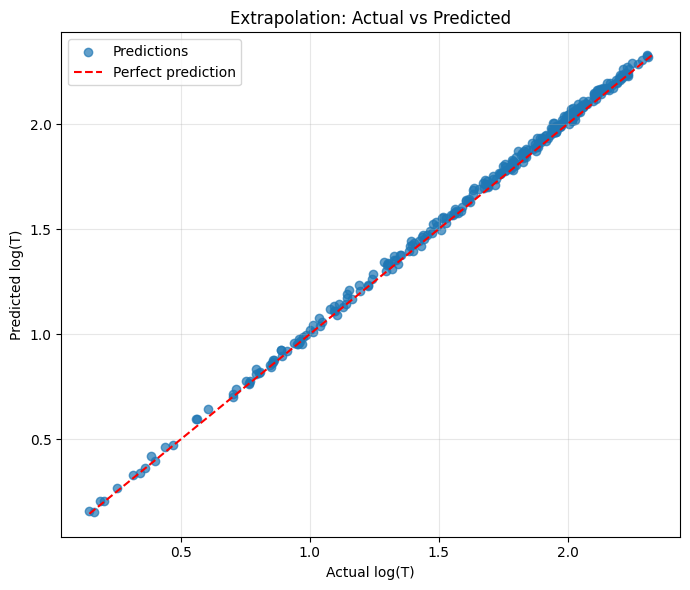

In [ ]:
# ACTUAL VS PREDICTED GRAPH
# ============================================

plt.figure(figsize=(7, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.7,
    label="Predictions"
)

limits = [
    min(y_test.min(), y_pred.min()),
    max(y_test.max(), y_pred.max())
]

plt.plot(
    limits,
    limits,
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual log(T)")
plt.ylabel("Predicted log(T)")

plt.title("Extrapolation: Actual vs Predicted")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

plt.savefig("extrapolation_predictions.png", dpi=300)

plt.show()

In [ ]:
# ERROR ANALYSIS
# ============================================

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

mae = mean_absolute_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("Mean Squared Error:", mse)

print("Root Mean Squared Error:", rmse)

print("Mean Absolute Error:", mae)

print("R-squared:", r2)


EXTRAPOLATION PERFORMANCE
Mean Squared Error: 0.0007633247574528695
Root Mean Squared Error: 0.027628332513071965
Mean Absolute Error: 0.02325081643409346
R-squared: 0.9970942912140919
